# Experiment 5: Regularization using Ridge and Lasso
**Aim:** Apply Ridge (L2) and Lasso (L1) regression and observe their effect on overfitting and multicollinearity.

**Dataset:** Diabetes (built into scikit-learn): 442 patients, 10 features (age, sex, bmi, bp, s1–s6 blood tests). Target = disease progression after one year.

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
data = load_diabetes(as_frame=True)
X = data.data
y = data.target
print("Shape:", X.shape)
X.head()

Shape: (442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## Check multicollinearity: correlation heatmap and VIF

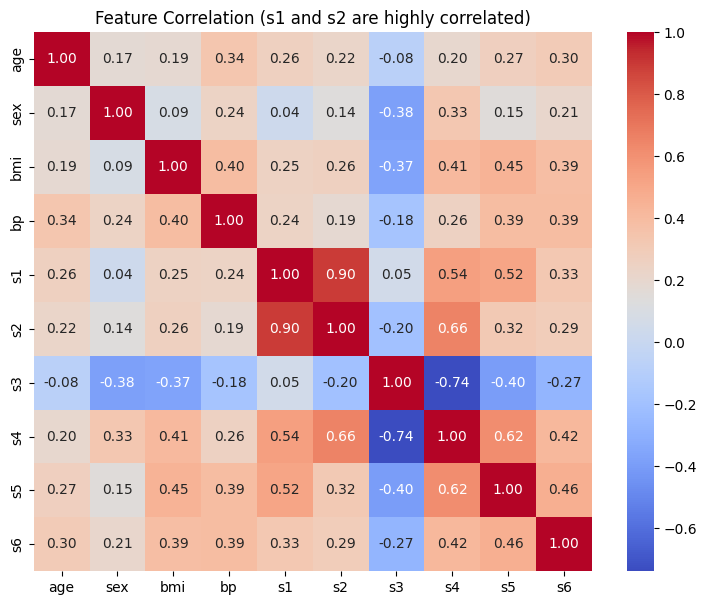

In [4]:
plt.figure(figsize=(9, 7))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation (s1 and s2 are highly correlated)")
plt.show()

In [5]:
# VIF = 1 / (1 - R2), where R2 comes from predicting one feature using all the others
# VIF > 10 means strong multicollinearity
vif = []
for col in X.columns:
    others = X.drop(columns=col)
    r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
    vif.append(round(1 / (1 - r2), 2))

pd.DataFrame({"Feature": X.columns, "VIF": vif})

,Feature,VIF
0,age,1.22
1,sex,1.28
2,bmi,1.51
3,bp,1.46
4,s1,59.20
5,s2,39.19
6,s3,15.40
7,s4,8.89
8,s5,10.08
9,s6,1.48


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Train Linear (no penalty), Ridge (L2 penalty) and Lasso (L1 penalty)

In [7]:
models = {
    "Linear (OLS)": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10),
    "Lasso (alpha=1)": Lasso(alpha=1),
}

results = []
coefs = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append([name,
                    mean_squared_error(y_train, model.predict(X_train)),
                    mean_squared_error(y_test, model.predict(X_test)),
                    r2_score(y_test, model.predict(X_test)),
                    np.sum(model.coef_ == 0)])
    coefs[name] = model.coef_

pd.DataFrame(results, columns=["Model", "Train MSE", "Test MSE", "Test R2", "Zero Coefficients"]).round(4)

,Model,Train MSE,Test MSE,Test R2,Zero Coefficients
0,Linear (OLS),2868.5497,2900.1936,0.4526,0
1,Ridge (alpha=10),2887.5157,2875.7787,0.4572,0
2,Lasso (alpha=1),2901.2161,2824.5681,0.4669,1


     Linear (OLS)  Ridge (alpha=10)  Lasso (alpha=1)
age          1.75              1.93             0.69
sex        -11.51            -11.03            -9.30
bmi         25.61             25.61            26.22
bp          16.83             16.30            15.66
s1         -44.45            -12.93            -8.23
s2          24.64              0.54            -0.00
s3           7.68             -6.13            -9.02
s4          13.14              8.57             3.42
s5          35.16             22.75            22.64
s6           2.35              2.92             2.10


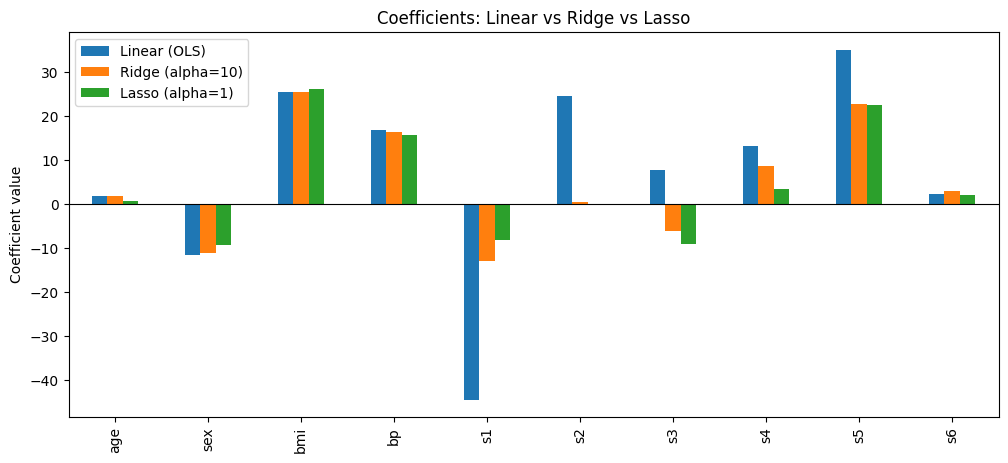

In [8]:
coef_df = pd.DataFrame(coefs, index=X.columns).round(2)
print(coef_df)

coef_df.plot(kind="bar", figsize=(12, 5))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Coefficients: Linear vs Ridge vs Lasso")
plt.ylabel("Coefficient value")
plt.show()

## Conclusion
- s1, s2, s3, s4, s5 have **high VIF** (s1 ≈ 59, s2 ≈ 39), so the features are multicollinear. Plain linear regression gives them large, unstable coefficients (s1 = −44, s2 = +25).
- **Ridge** shrinks all coefficients towards zero (s1 → −13, s2 → 0.5) but keeps every feature.
- **Lasso** sets some coefficients **exactly to zero** (s2 = 0), so it also does feature selection.
- Both regularized models have slightly **higher train error but lower test error** than plain linear regression, so they reduce overfitting.